**import**

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (train_test_split, GridSearchCV)

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor

from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score)

**load dataset**

In [2]:
df = pd.read_csv("./student_dataset.csv")

df.sample(5)

,StudyHours,Attendence,Assignments,Marks
23,6,99,3,77
199,6,71,8,83
184,3,68,7,61
104,8,94,2,94
18,6,100,9,90


**Basic Data Exploration**

In [3]:
print(df.shape)

print(df.info())

print(df.describe())

print(df.isnull().sum())

print(df.duplicated().sum())

(200, 4)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   StudyHours   200 non-null    int64
 1   Attendence   200 non-null    int64
 2   Assignments  200 non-null    int64
 3   Marks        200 non-null    int64
dtypes: int64(4)
memory usage: 6.4 KB
None
       StudyHours  Attendence  Assignments       Marks
count  200.000000  200.000000    200.00000  200.000000
mean     5.560000   81.250000      4.87500   76.710000
std      2.899731   11.778419      3.14944   13.318514
min      1.000000   60.000000      0.00000   48.000000
25%      3.000000   71.750000      2.00000   66.750000
50%      6.000000   82.000000      4.00000   78.000000
75%      8.000000   92.000000      8.00000   87.250000
max     10.000000  100.000000     10.00000  100.000000
StudyHours     0
Attendence     0
Assignments    0
Marks          0
dtype: int64
2


**Data Cleaning**

*Missing Values*

In [4]:
df.fillna(df.mean(numeric_only = True), inplace = True)

*Duplicate Records*

In [5]:
duplicates = df.duplicated().sum()

print(f"Duplicate Rows: {duplicates}")

df.drop_duplicates(inplace = True)

Duplicate Rows: 2


**EDA**

*Correlation Heatmap*

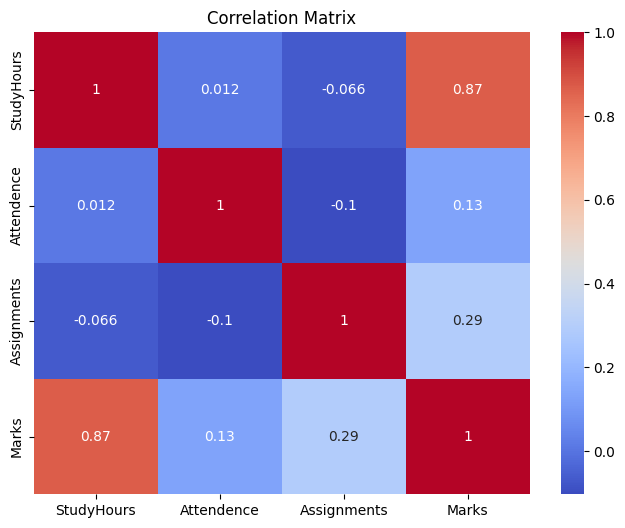

In [6]:
plt.figure(figsize = (8,6))

sns.heatmap(df.corr(), annot = True, cmap = "coolwarm")

plt.title("Correlation Matrix")
plt.show()

*Distribution of Marks*

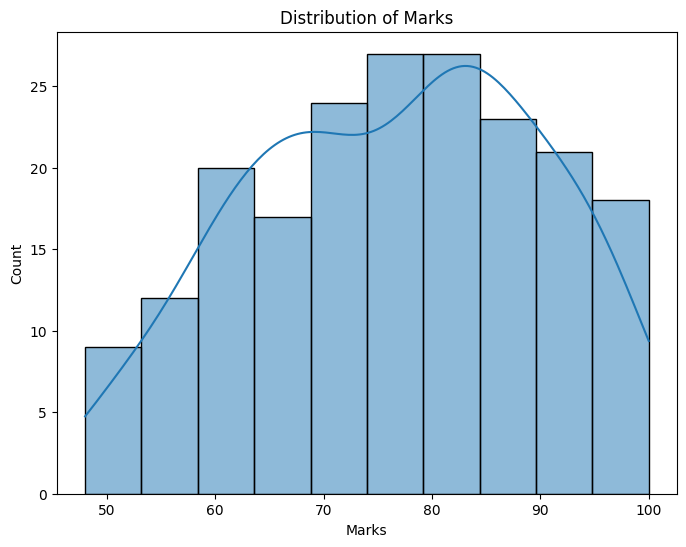

In [7]:
plt.figure(figsize = (8,6))

sns.histplot(data = df, x = "Marks", bins = 10, kde = True)

plt.title("Distribution of Marks")
plt.show()

*Feature vs Target*

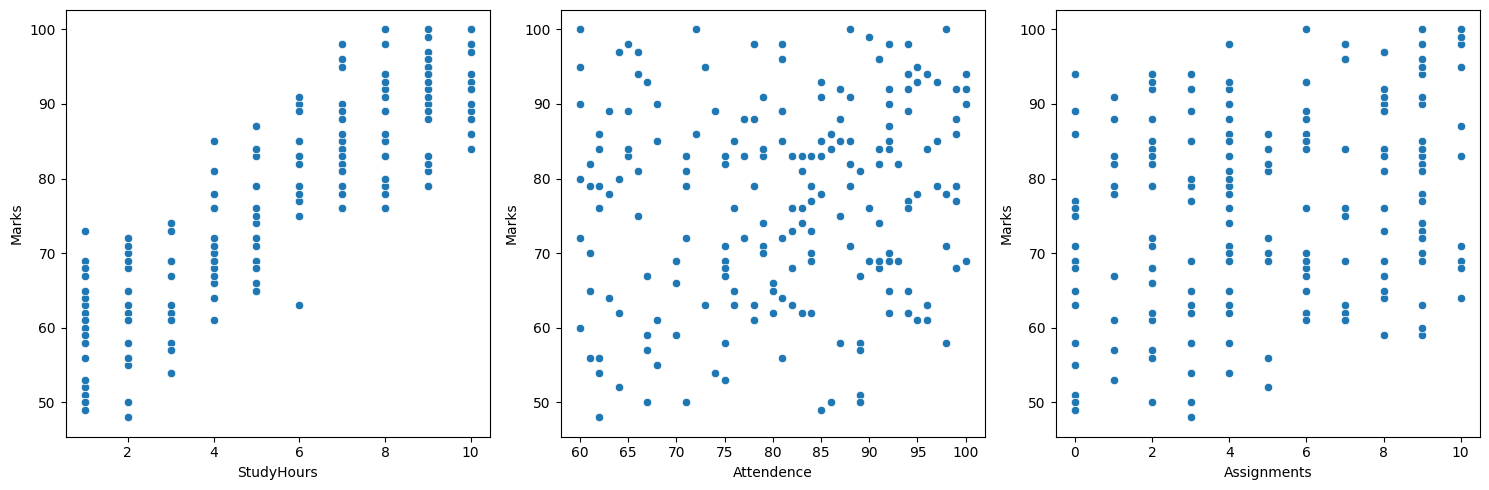

In [9]:
fig, axes = plt.subplots(1,3, figsize = (15,5))

sns.scatterplot(data = df, x = "StudyHours", y = "Marks", ax = axes[0])

sns.scatterplot(data = df, x = "Attendence", y = "Marks", ax = axes[1])

sns.scatterplot(data = df, x = "Assignments", y = "Marks", ax = axes[2])

plt.tight_layout()
plt.show()

**Data Splitting**

In [10]:
X = df.drop("Marks", axis = 1)
y = df["Marks"]

X_train, X_test,y_train, y_test = train_test_split(X,y, test_size = 0.2, random_state = 42)

**Models**

*Model 1: Linear Regression*

In [11]:
lr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

lr_pipeline.fit(X_train,y_train)
lr_pred = lr_pipeline.predict(X_test)

*Model 2: KNN*

In [12]:
knn_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", KNeighborsRegressor())
])

knn_params = {
    "model__n_neighbors" : [3,5,7,9,11],
    "model__weights" : ["uniform","distance"],
    "model__p" : [1,2]
}

knn_grid = GridSearchCV(knn_pipeline, knn_params, cv = 5, scoring = "r2", n_jobs = -1)

knn_grid.fit(X_train,y_train)

print(knn_grid.best_params_)

knn_pred = knn_grid.predict(X_test)

{'model__n_neighbors': 9, 'model__p': 1, 'model__weights': 'distance'}


*Model 3: Random Forest + GridSearchCV*

In [14]:
rf_pipeline = Pipeline([
    ("model", RandomForestRegressor(random_state = 42))
])

rf_params = {
    "model__n_estimators" : [100,200,300],
    "model__max_depth" : [None, 5, 10],
    "model__min_samples_split" : [2,5]
}

rf_grid = GridSearchCV(rf_pipeline, rf_params, cv = 5, scoring = "r2", n_jobs = -1)

rf_grid.fit(X_train,y_train)

print(rf_grid.best_params_)

rf_pred = rf_grid.predict(X_test)

{'model__max_depth': None, 'model__min_samples_split': 2, 'model__n_estimators': 200}


**Evaluation Function**

In [15]:
def evaluation(y_true, y_pred):
  r2 = r2_score(y_true, y_pred)

  rmse = np.sqrt(mean_squared_error(y_true,y_pred))

  mae = mean_absolute_error(y_true, y_pred)

  return r2, rmse, mae

**Compare model**

In [18]:
results = []
models = {
    "Linear Regression" : lr_pred,
    "KNN" : knn_pred,
    "Random Forest" : rf_pred
}

for name, pred in models.items():
  r2, rmse, mae = evaluation(y_test,pred)

  results.append([name, r2, rmse, mae])

  results_df = pd.DataFrame(results, columns = ["Model", "R2","RMSE","MAE"])

  print(results_df)

               Model        R2      RMSE       MAE
0  Linear Regression  0.885078  4.062228  3.152699
               Model        R2      RMSE       MAE
0  Linear Regression  0.885078  4.062228  3.152699
1                KNN  0.862512  4.443190  3.536373
               Model        R2      RMSE       MAE
0  Linear Regression  0.885078  4.062228  3.152699
1                KNN  0.862512  4.443190  3.536373
2      Random Forest  0.862209  4.448083  3.569194


**Best Model**

In [19]:
best_model = results_df.sort_values(by = "R2", ascending = False)
print(best_model)

               Model        R2      RMSE       MAE
0  Linear Regression  0.885078  4.062228  3.152699
1                KNN  0.862512  4.443190  3.536373
2      Random Forest  0.862209  4.448083  3.569194


In [20]:
import pickle

pickel_model_path = "best_model.pkl"
with open(pickel_model_path, "wb") as f:
  pickle.dump(lr_pipeline, f)